In [1]:
%load_ext autoreload
%autoreload 2

# Noiseless

## Simulation settings

In [2]:
from utils.hexec import create_estimator_options
from utils.hexec import ExecDB
import numpy as np

L_arr = [8]
J_arr = [1]
h_arr = [0.05]
lamb_arr = [0.7]
g_arr = [None]

x_basis = False

particle_pair_left_positions = [L//2 - 1 for L in L_arr]
particle_pair_length = 1

final_time = 8
steps = 35
max_layers = 50

error_to_adjust = 1e-2

shots = [50000]

execution_database = "z2_chain_jobs_postselection.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

## Circuit generation & observables

In [3]:
from z2chain.circs import erradj_particle_pair_quench_simulation_circuits
from z2chain.operators import local_pauli_x, local_pauli_z
from utils.circs import generate_and_save_circs
from qiskit_aer import AerSimulator
from itertools import product
from functools import partial
import numpy as np
import os

optimization_level = 3

circuits = [] # circuits[L][Jhλg][t]
observable_generating_funcs = [] #observable_generating_funcs[L][i]
postselection_operators_funcs = []

estimator_options = [{
    "default_precision": 1e-5
}]

simulator_options = [{
    "method": "matrix_product_state",
    "matrix_product_state_max_bond_dimension": 256,
    "matrix_product_state_truncation_threshold": 1e-10
}]

backend = AerSimulator(**simulator_options[0])

for L, pp_ps in zip(L_arr, particle_pair_left_positions):
    this_circuits = []
    for Ji, hi, lambi, gi in product(range(len(J_arr)), range(len(h_arr)), range(len(lamb_arr)), range(len(g_arr))):
        circuit_filepath = os.path.join(circ_folder_path, f"z2chain_quench_circs_simulation_maxt_{final_time}_steps_{steps}_L_{L}_J_{J_arr[Ji]:.04f}_h_{h_arr[hi]:.04f}_lamb_{lamb_arr[lambi]:.04f}_g_{g_arr[gi]}_pp_{pp_ps}_pl_{particle_pair_length}_xbasis_{x_basis}_errtoadj_{error_to_adjust}_max_layers_{max_layers}.qpy")
        qubits_inds = np.arange(2*L-1).tolist()
        circs_func_args = (L, J_arr[Ji], h_arr[hi], lamb_arr[lambi], pp_ps, particle_pair_length, final_time, steps, backend, optimization_level, max_layers, error_to_adjust, g_arr[gi], qubits_inds, x_basis, False, False)
        circuit = generate_and_save_circs(circuit_filepath, erradj_particle_pair_quench_simulation_circuits, *circs_func_args)
        this_circuits.append(circuit)
    circuits.append(this_circuits)

# circuits[0][0][1].draw(output="mpl", idle_wires=False)

In [4]:
from utils.circs import depth2qb

[depth2qb(circ) for circ in circuits[0][0]]

[0,
 8,
 12,
 20,
 24,
 32,
 36,
 40,
 48,
 52,
 60,
 64,
 72,
 76,
 80,
 88,
 92,
 100,
 104,
 112,
 116,
 120,
 128,
 132,
 140,
 144,
 152,
 156,
 160,
 168,
 172,
 180,
 184,
 192,
 196,
 200]

## Simulation 

In [6]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix, convert_jobs_to_site_gauge_matrix
from utils.hexec import execute_estimator_batch
from utils.sexec import execute_simulation_estimator_batch

overwrite = True

jobs = [] # jobs[L][opts][Jhλg][t]

for i, L in enumerate(L_arr):
    this_L_jobs = []
    for estimator_opt, simulator_opt in zip(estimator_options, simulator_options):
        this_opts_jobs = []
        for j, (J, h, lamb, g) in enumerate(product(J_arr, h_arr, lamb_arr, g_arr)):
            filepath = f"Results/tncirc_z2pairquench_maxt_{final_time}_steps_{steps}_L_{L}_J_{J}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g}_pp_{particle_pair_left_positions[i]}_pl_{particle_pair_length}_xbasis_{x_basis}_bd_{simulator_opt["matrix_product_state_max_bond_dimension"]}_prec_{estimator_opt['default_precision']}_errtoadj_{error_to_adjust}_max_layers_{max_layers}.txt"
            if os.path.exists(filepath) and not overwrite:
                this_jobs = load_site_gauge_observable_matrix(filepath)
            else:
                observable_generating_funcs = [partial(local_pauli_z if not x_basis else local_pauli_x, qubit_ind=i) for i in range(2*L-1)]
                this_jobs = execute_simulation_estimator_batch(simulator_opt, estimator_opt, circuits[i][j], observable_generating_funcs)
                this_jobs = convert_jobs_to_site_gauge_matrix(this_jobs)
                save_site_gauge_observable_matrix(this_jobs, filepath)
            this_opts_jobs.append(this_jobs)
        this_L_jobs.append(this_opts_jobs)
    jobs.append(this_L_jobs)

## Plots

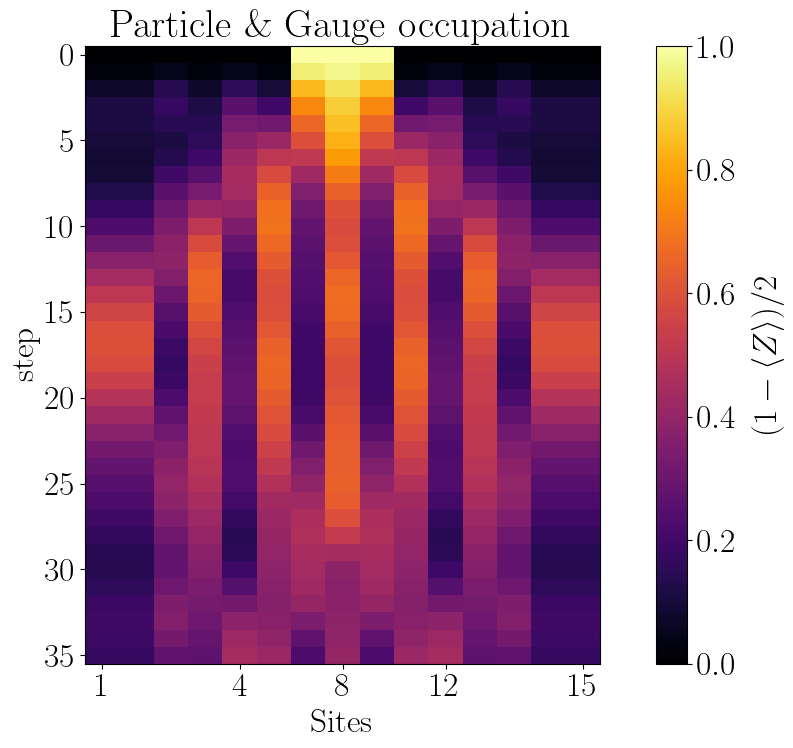

In [7]:
from z2chain.plotting import x_t_plot

for i, L in enumerate(L_arr):
    for j, (estimator_opt, simulator_opt) in enumerate(zip(estimator_options, simulator_options)):
        for Ji, hi, lambi, gi in product(range(len(J_arr)), range(len(h_arr)), range(len(lamb_arr)), range(len(g_arr))):
            job_ind = gi + lambi*len(g_arr) + hi*len(g_arr)*len(lamb_arr) + Ji*len(g_arr)*len(lamb_arr)*len(h_arr)
            x_t_plot(jobs[i][j][job_ind], filepath=f"Plots/tncirc_z2pairquench_maxt_{final_time}_steps_{steps}_L_{L}_J_{J_arr[Ji]:.04f}_h_{h_arr[hi]:.04f}_lamb_{lamb_arr[lambi]:.04f}_g_{g_arr[gi]}_pp_{particle_pair_left_positions[i]}_pl_{particle_pair_length}_xbasis_{x_basis}_bd_{simulator_opt["matrix_product_state_max_bond_dimension"]}_prec_{estimator_opt['default_precision']}_errtoadj_{error_to_adjust}_max_layers_{max_layers}.png")

## Comparison with exact dynamics

In [8]:
import z2chain.exact as z2ced

overwrite = True

occupations = []
for L, pp_ps in zip(L_arr, particle_pair_left_positions):
    this_occupations = []
    for J, h, lamb, g in product(J_arr, h_arr, lamb_arr, g_arr):
        results_filepath = f"Results/dual_z2ppairquench_maxt_{final_time}_steps_{steps}_L_{L}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_pp_{pp_ps}_pl_1.txt"
        occupation_site_gauge_matrix = z2ced.dual_particle_pair_quench_simulation(L, J, h, lamb, pp_ps, final_time, steps, results_filepath, overwrite=overwrite, print_mode=True)
        this_occupations.append(occupation_site_gauge_matrix)
    occupations.append(this_occupations)

t = 153.1250 / t_f = 153.1250                    

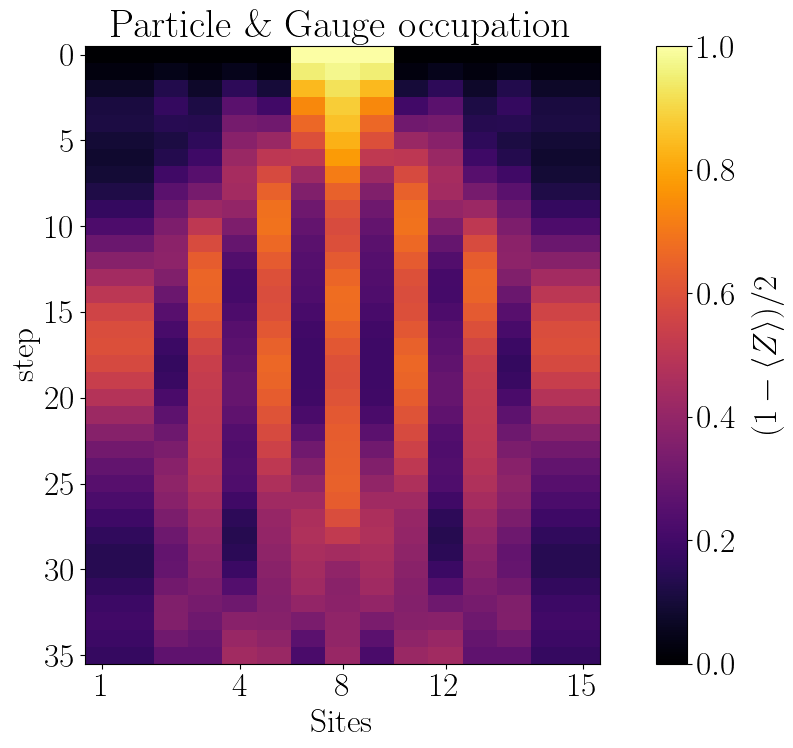

In [9]:
from z2chain.plotting import x_t_plot

for i, L in enumerate(zip(L_arr)):
    for j, (J, h, lamb, g) in enumerate(product(J_arr, h_arr, lamb_arr, g_arr)):
            job_ind = gi + lambi*len(g_arr) + hi*len(g_arr)*len(lamb_arr) + Ji*len(g_arr)*len(lamb_arr)*len(h_arr)
            x_t_plot(occupations[i][j])

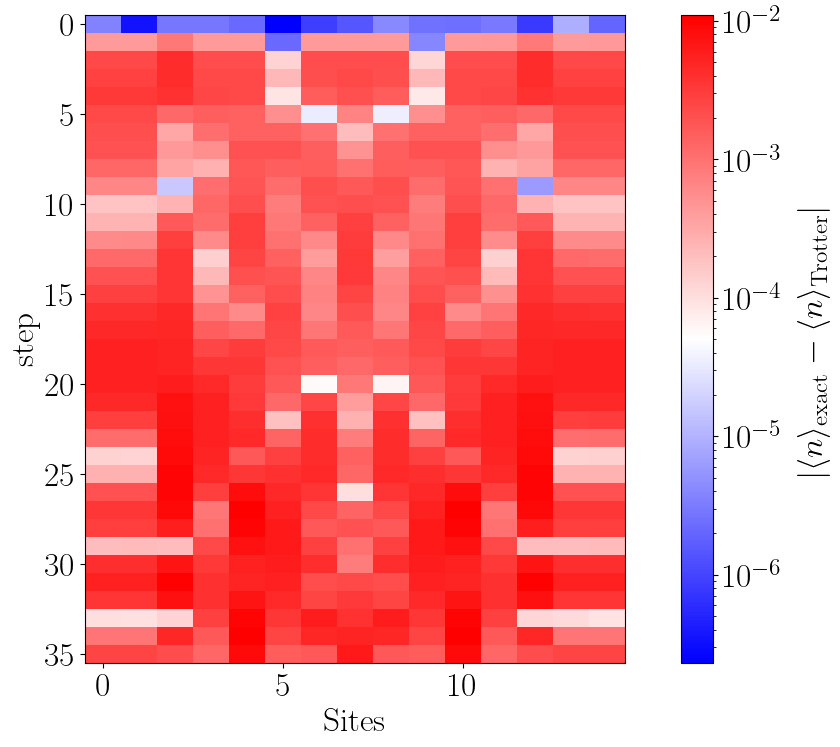

In [10]:
from z2chain.plotting import discrepancies_plot

for i, L in enumerate(zip(L_arr)):
    for j, (J, h, lamb, g) in enumerate(product(J_arr, h_arr, lamb_arr, g_arr)):
        discrepancies_plot(occupations[i][j], jobs[i][j][0])

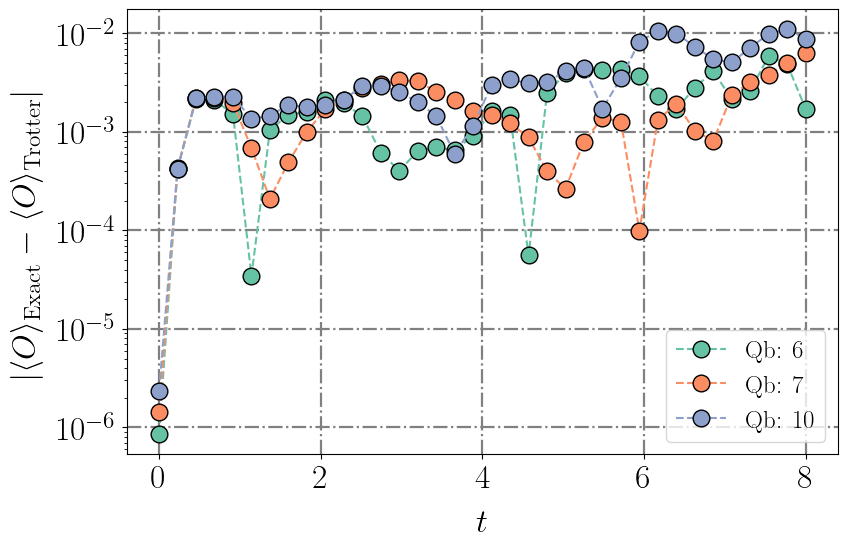

In [11]:
from z2chain.plotting import plot_single_qubit_discrepancies
from utils.circs import depth2qb

qubit_inds = [6, 7, 10]

x_plot = np.linspace(0, final_time, steps+1)
x_label = "$t$"
# x_label = "2Qb Depth"

for i, L in enumerate(zip(L_arr)):
    for j, (J, h, lamb, g) in enumerate(product(J_arr, h_arr, lamb_arr, g_arr)):
        # x_plot = [depth2qb(circ) for circ in circuits[i][j]][1::]
        plot_single_qubit_discrepancies(occupations[i][j], jobs[i][j][0], qubit_inds=qubit_inds, x_plot=x_plot, x_label=x_label)

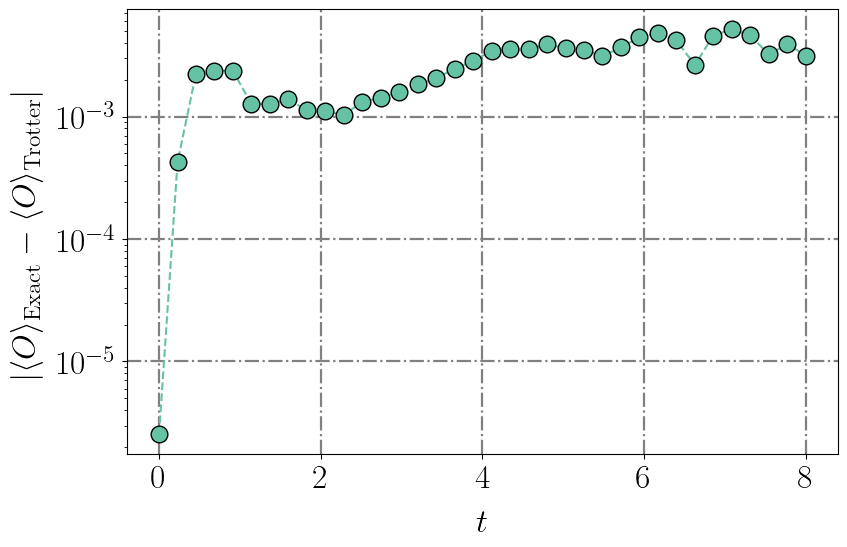

In [12]:
from z2chain.plotting import plot_average_discrepancy

x_plot = np.linspace(0, final_time, steps+1)
x_label = "$t$"

for i, L in enumerate(zip(L_arr)):
    for j, (J, h, lamb, g) in enumerate(product(J_arr, h_arr, lamb_arr, g_arr)):
        # x_plot = [depth2qb(circ) for circ in circuits[i][j]][1::]
        plot_average_discrepancy(occupations[i][j], jobs[i][j][0], x_plot=x_plot, x_label=x_label)